## Setup
Import the libraries used for data handling, modelling and plotting, and point to the `data/` folder that holds the dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import seaborn as sns
# The dataset (Portugal Real Estate 2024, Kaggle: luvathoms/portugal-real-estate-2024)
# is included in the data/ folder of this repository
path = "data"

## Load the data
Read the Portugal real estate listings CSV, loading a few mixed-type columns as strings.

In [2]:
df = pd.read_csv(
    path + "/portugal_listinigs.csv",
    dtype={
        9: str,
        10: str,
        12: str,
        13: str,
        14: str,
        15: str,
        16: str,
        20: str
    }
)

## Filter and clean
Keep apartments and duplexes in the Lisbon district, select the relevant columns, convert parking and elevator flags to booleans, derive property age, and remove listings with a missing price or implausible area or bathroom values.

In [3]:
colunas_interesse = [
    "Price", "District", "City", "Town", "Type", "TotalArea",
    "HasParking", "ConstructionYear", "Elevator",
    "TotalRooms", "NumberOfBathrooms"
]

df_processed = df[df["District"] == "Lisboa"][colunas_interesse].copy()
df_processed = df_processed.drop(columns=['District'])
df_processed = df_processed.rename(columns={"Elevator": "HasElevator"})


df_processed["HasParking"] = (df_processed["HasParking"] == "True")
df_processed["HasElevator"] = (df_processed["HasElevator"] == "True")

tipos_validos = ["Apartment", "Duplex"]
df_processed = df_processed[df_processed["Type"].isin(tipos_validos)].copy()

df_processed['Age'] = 2024 - df_processed['ConstructionYear']
df_processed = df_processed.drop(columns=['ConstructionYear'])

df_processed.dropna(subset=['Price'], inplace=True)

print("TotalArea percentile check:")
print(f"P1: {df_processed['TotalArea'].quantile(0.01):.1f} m²")
print(f"P99: {df_processed['TotalArea'].quantile(0.99):.1f} m²")

df_processed = df_processed[
    (df_processed["TotalArea"] <= 10000) &
    (df_processed["TotalArea"] > 20) &
    (df_processed["NumberOfBathrooms"] >= 0)
]



TotalArea percentile check:
P1: 0.0 m²
P99: 1120.0 m²


/tmp/ipykernel_15634/2827143467.py:21: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_processed.dropna(subset=['Price'], inplace=True)


## Train and evaluate the model
Build a preprocessing pipeline (median imputation for numeric features, one-hot encoding for categorical ones) with a random forest regressor, train it on an 80/20 split and report R², MAE, RMSE and MAPE on the test set.

In [4]:
X = df_processed.drop(columns=['Price'])
y = df_processed['Price']

num_cols = ['TotalArea', 'Age', 'TotalRooms', 'NumberOfBathrooms']
bool_cols = ['HasParking', 'HasElevator']
cat_cols = ['City', 'Town', 'Type']

num_transformer = SimpleImputer(strategy='median')

cat_transformer = make_pipeline(
    SimpleImputer(strategy='most_frequent'),
    OneHotEncoder(handle_unknown='ignore')
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols),
        ('bool', 'passthrough', bool_cols)
    ],
    remainder='drop'
)

pipe_model = make_pipeline(
    preprocessor,
    RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
pipe_model.fit(X_train, y_train)

y_pred = pipe_model.predict(X_test)

r2_score = pipe_model.score(X_test, y_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f"R²: {r2_score:.2f}")
print(f"MAE: {mae:,.2f} €")
print(f"RMSE: {rmse:,.2f} €")
print(f"MAPE: {mape:.2f}%")

R²: 0.89
MAE: 70,818.69 €
RMSE: 153,036.23 €
MAPE: 15.13%


## Exploratory plots
Plot average price by property type, price against total area, the price distribution, prices by city, and a correlation matrix of the numeric features.

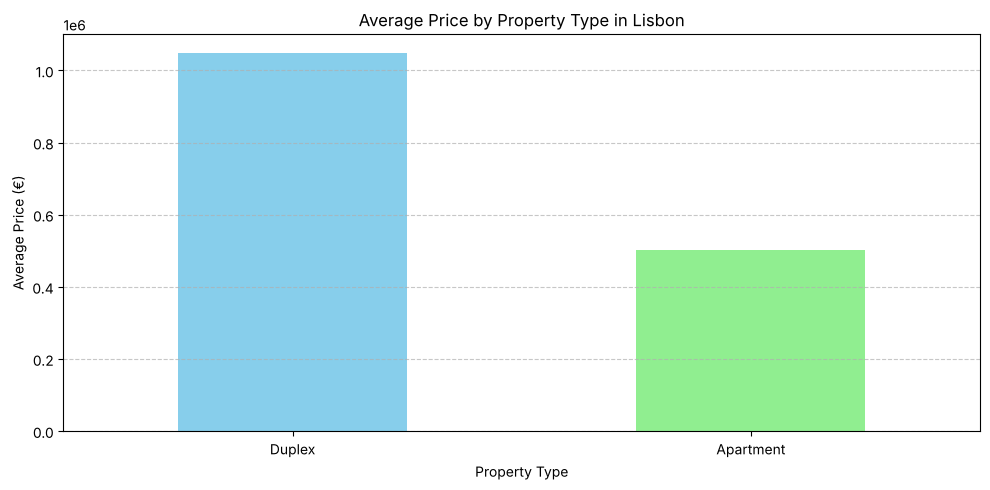

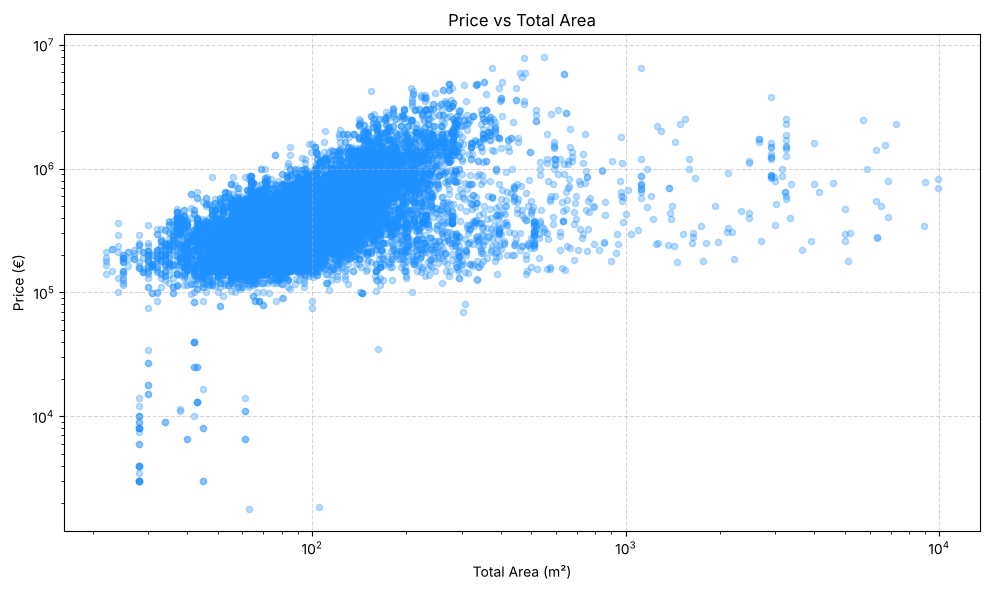

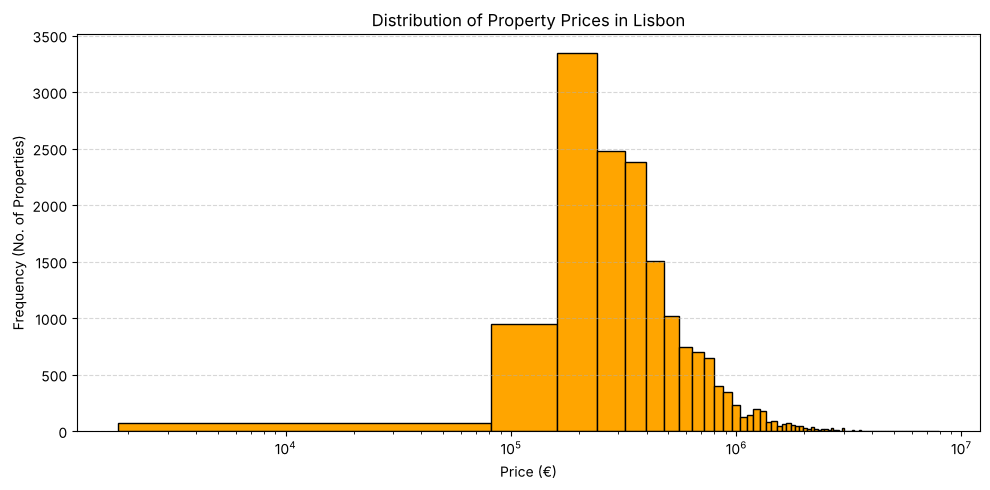

<Figure size 1200x800 with 0 Axes>

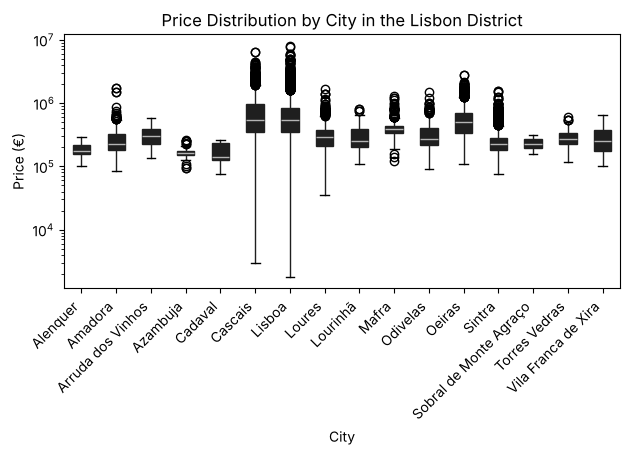

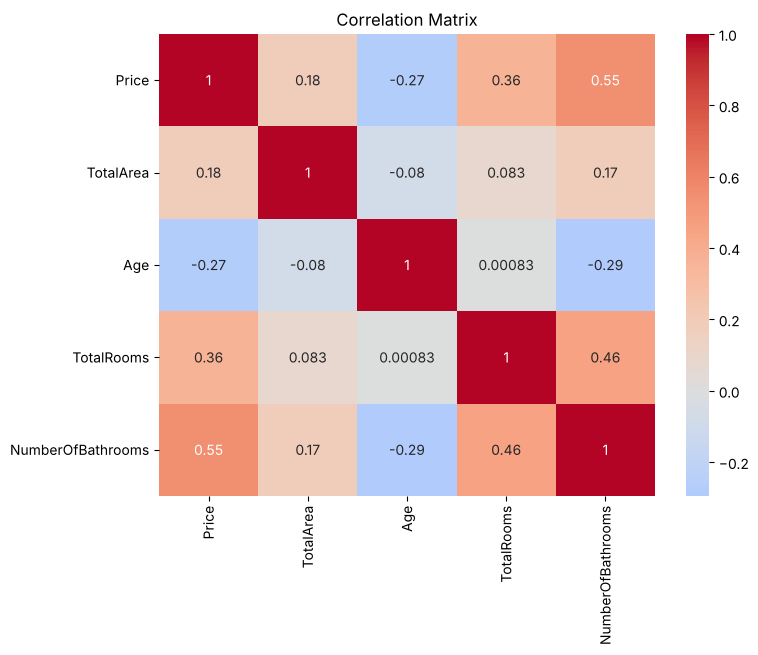

In [5]:
plt.figure(figsize=(10, 5))

avg_price_type = df_processed.groupby("Type")["Price"].mean().sort_values(ascending=False)

avg_price_type.plot(kind='bar', color=['skyblue', 'lightgreen'])
plt.title("Average Price by Property Type in Lisbon")
plt.ylabel("Average Price (€)")
plt.xlabel("Property Type")
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("Image1.png")
plt.show()

plt.figure(figsize=(10, 6))
plt.scatter(df_processed["TotalArea"], df_processed["Price"], alpha=0.3, s=20, c='dodgerblue')
plt.title("Price vs Total Area")
plt.xlabel("Total Area (m²)")
plt.ylabel("Price (€)")
plt.yscale('log')
plt.xscale('log')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("Image2.png")
plt.show()


plt.figure(figsize=(10, 5))
plt.hist(df_processed["Price"], bins=100, color='orange', edgecolor='black')
plt.title("Distribution of Property Prices in Lisbon")
plt.xlabel("Price (€)")
plt.ylabel("Frequency (No. of Properties)")
plt.xscale('log')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("Image3.png")
plt.show()

plt.figure(figsize=(12, 8))
df_processed.boxplot(
    column="Price",
    by="City",
    grid=False,
    vert=True,
    patch_artist=True
)
plt.title("Price Distribution by City in the Lisbon District")
plt.suptitle("")
plt.ylabel("Price (€)")
plt.xlabel("City")
plt.xticks(rotation=45, ha='right')
plt.yscale('log')
plt.tight_layout()
plt.savefig("Image4.png")
plt.show()


corr = df_processed[['Price', 'TotalArea', 'Age', 'TotalRooms', 'NumberOfBathrooms']].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0)
plt.title("Correlation Matrix")
plt.show()